
# Task 1 — Data Audit & Exploration

**Project:** GrowMar Employee Attrition ML

**Objective:** Audit the employee dataset for structural issues, missing values, outliers, class imbalance, and data leakage risks.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, JupyterLab, Docker.

**Target variable:** `left_within_12m`

**Purpose:** Produce a reproducible audit notebook and a clear report documenting findings and decisions before building machine learning models.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project paths
PROJECT_ROOT = Path("/workspace")
DATA_DIR = PROJECT_ROOT / "data"
REPORT_DIR = PROJECT_ROOT / "reports"

print("Environment ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Data directory:", DATA_DIR)

Environment ready!
Pandas version: 3.0.6
NumPy version: 2.5.4
Data directory: /workspace/data


In [2]:
import os
from pathlib import Path

print("Current working directory:", os.getcwd())
print("Workspace exists:", Path("/workspace").exists())
print("CSV exists:", Path("/workspace/data/attrition_dataset.csv").exists())

Current working directory: /workspace/notebooks
Workspace exists: True
CSV exists: True


In [3]:
df = pd.read_csv("/workspace/data/attrition_dataset.csv")


## 1. Dataset Overview

The purpose of this section is to understand the size and structure of the employee dataset before performing further analysis.


In [4]:

# Dataset overview

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())


Number of rows: 2389
Number of columns: 42

Column names:
['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2389 entri

,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
0,1,EMP-0002,2025-09-30,D08,R047,4,Pune,Remote,Permanent,B.E. Computer Science,...,5,0.2353,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
1,2,EMP-0004,2025-09-30,D03,R017,3,Erode,Hybrid,Permanent,MCA,...,4,0.0556,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2,3,EMP-0011,2025-09-30,D07,R039,1,Kochi,Hybrid,Permanent,M.A. Social Work,...,7,0.0000,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
3,4,EMP-0012,2025-09-30,D01,R004,2,Chennai,Onsite,Permanent,B.Tech Information Technology,...,8,0.1448,1,1,master_employee_snapshot,2026-04-23,2026-03-24,Work-Life Balance,Y,"117,098.85"
4,5,EMP-0013,2025-09-30,D04,R023,2,Chennai,Onsite,Permanent,B.E. Mechanical,...,7,0.2051,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN



## 2. Column Summary

This section examines the data type, missing values, and distinct values in each column. It helps identify fields that require further investigation.


In [5]:

# Column summary

column_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(column_summary)


,Data Type,Missing Values,Missing Percentage,Unique Values
row_id,int64,0,0.00,2389
employee_id,str,0,0.00,2383
observation_date,str,0,0.00,1135
department_id,str,0,0.00,10
role_id,str,0,0.00,48
job_level,int64,0,0.00,6
work_location,str,0,0.00,16
work_mode,str,0,0.00,3
employment_type,str,0,0.00,2
highest_education,str,15,0.63,27


In [6]:

# Check exact duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)


Number of exact duplicate rows: 0


Target column distribution:
left_within_12m
0    2040
1     349
Name: count, dtype: int64

Target distribution in percentage:
left_within_12m
0    85.39
1    14.61
Name: proportion, dtype: float64


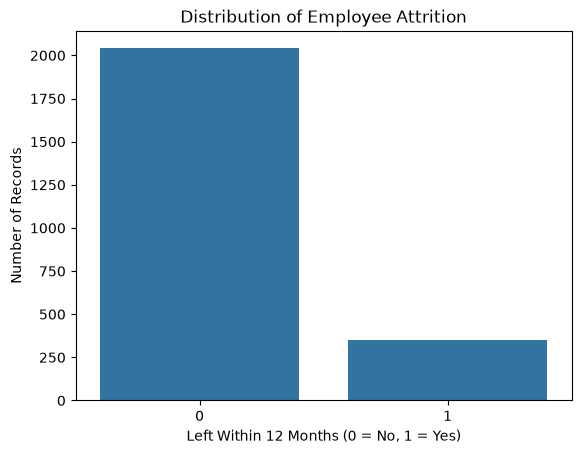

In [7]:
# Check the distribution of the target column
print("Target column distribution:")
print(df["left_within_12m"].value_counts())

print("\nTarget distribution in percentage:")
print((df["left_within_12m"].value_counts(normalize=True) * 100).round(2))

# Visualize the target distribution
sns.countplot(data=df, x="left_within_12m")
plt.title("Distribution of Employee Attrition")
plt.xlabel("Left Within 12 Months (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.savefig(
    "/workspace/reports/attrition_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 3. Missing Value Analysis

This section identifies missing values in the dataset and calculates their percentage for each column. The results help determine which columns require further investigation and how missing data should be handled during preprocessing.

In [8]:
# Missing value analysis
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

# Display columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
]

# Display the 10 columns with the most missing values
display(
    missing_summary.sort_values(
        by="Missing Percentage",
        ascending=False
    ).head(10)
)

,Missing Values,Missing Percentage
resignation_date,2068,86.56
exit_date,2040,85.39
exit_reason,2040,85.39
fnf_settlement_amount,2040,85.39
exit_interview_done,2040,85.39
months_since_last_promotion,1459,61.07
last_engagement_score,528,22.10
last_raise_pct,202,8.46
last_performance_rating,182,7.62
commute_distance_km,55,2.30


## 4. Duplicate Record Analysis

This section checks for exact duplicate rows in the dataset. Duplicate records may affect statistical analysis and model performance, so they should be investigated before deciding whether any records need to be removed.

In [9]:
# Check for exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 0


## 5. Outlier Detection

This section identifies unusual values in numerical features that may indicate extreme employee characteristics or potential data quality issues. The Interquartile Range (IQR) method and Z-score method will be used to detect potential outliers. These values will be investigated before deciding whether any action is necessary.

In [10]:
# Identify numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical columns:", len(numeric_columns))
print("\nNumerical columns:")

for i, column in enumerate(numeric_columns, start=1):
    print(f"{i}. {column}")

Number of numerical columns: 28

Numerical columns:
1. row_id
2. job_level
3. tenure_months
4. total_experience_years
5. previous_employers_count
6. commute_distance_km
7. annual_fixed_pay
8. comp_ratio
9. raises_received
10. last_raise_pct
11. months_since_last_raise
12. promotions_received
13. months_since_last_promotion
14. internal_transfers
15. last_performance_rating
16. last_engagement_score
17. manager_changes_12m
18. training_hours_12m
19. attendance_rate_3m
20. late_arrivals_3m
21. avg_overtime_hours_per_month_3m
22. avg_hours_worked_3m
23. wfh_share_3m
24. unpaid_leave_days_6m
25. paid_leave_days_6m
26. dept_attrition_rate_prior_12m
27. left_within_12m
28. voluntary_left_within_12m


### 5.1 Selecting Numerical Features

Not all numerical columns are suitable for outlier detection. Identifier columns and target variables are excluded because they do not represent continuous measurements. We will focus on employee-related numerical features such as salary, tenure, working hours, and attendance.

In [11]:
# Select the required columns
outlier_columns = [
    "annual_fixed_pay",
    "avg_hours_worked_3m",
    "tenure_months"
]

# Detect outliers using the IQR method
for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of potential outliers:", len(outliers))


Column: annual_fixed_pay
Lower bound: -991542.0
Upper bound: 2841498.0
Number of potential outliers: 94

Column: avg_hours_worked_3m
Lower bound: 7.93
Upper bound: 9.4
Number of potential outliers: 48

Column: tenure_months
Lower bound: -31.5
Upper bound: 100.5
Number of potential outliers: 74


### 5.2 Outlier Detection Using the Z-score Method

The Z-score method measures how far a value is from the mean in terms of standard deviations. Values with an absolute Z-score greater than 3 are flagged as potential outliers. The results will be compared with the IQR method to understand how the two approaches identify unusual values.

In [12]:
# Detect outliers using the Z-score method
from scipy import stats
for column in outlier_columns:
    values = df[column].dropna()

    z_scores = stats.zscore(values)

    outlier_count = (abs(z_scores) > 3).sum()

    print(f"\nColumn: {column}")
    print("Number of potential outliers:", outlier_count)


Column: annual_fixed_pay
Number of potential outliers: 26

Column: avg_hours_worked_3m
Number of potential outliers: 15

Column: tenure_months
Number of potential outliers: 42


### 5.3 Comparison of IQR and Z-score Methods

This section compares the number of potential outliers detected by the IQR and Z-score methods for salary, average working hours, and employee tenure. Differences in the results help identify how each method responds to the distribution of the data.

In [13]:
# Compare IQR and Z-score results
comparison = []

for column in outlier_columns:
    values = df[column].dropna()

    # IQR method
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    # Z-score method
    z_scores = stats.zscore(values)
    zscore_count = (abs(z_scores) > 3).sum()

    # Store results
    comparison.append({
        "Feature": column,
        "IQR Outliers": int(iqr_count),
        "Z-score Outliers": int(zscore_count)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Feature,IQR Outliers,Z-score Outliers
0,annual_fixed_pay,94,26
1,avg_hours_worked_3m,48,15
2,tenure_months,74,42


## 6. Data Leakage Analysis

Data leakage occurs when information that would not be available at prediction time is used as a model feature. This can lead to misleading model performance. In this section, we will review columns that may reveal future employee attrition and identify fields that should be excluded from model training.

In [14]:
# Display all dataset columns for leakage review
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. row_id
2. employee_id
3. observation_date
4. department_id
5. role_id
6. job_level
7. work_location
8. work_mode
9. employment_type
10. highest_education
11. tenure_months
12. total_experience_years
13. previous_employers_count
14. commute_distance_km
15. annual_fixed_pay
16. comp_ratio
17. raises_received
18. last_raise_pct
19. months_since_last_raise
20. promotions_received
21. months_since_last_promotion
22. internal_transfers
23. last_performance_rating
24. last_engagement_score
25. manager_changes_12m
26. training_hours_12m
27. attendance_rate_3m
28. late_arrivals_3m
29. avg_overtime_hours_per_month_3m
30. avg_hours_worked_3m
31. wfh_share_3m
32. unpaid_leave_days_6m
33. paid_leave_days_6m
34. dept_attrition_rate_prior_12m
35. left_within_12m
36. voluntary_left_within_12m
37. source
38. exit_date
39. resignation_date
40. exit_reason
41. exit_interview_done
42. fnf_settlement_amount


In [15]:
# Columns requiring data leakage review
review_columns = [
    "row_id",
    "employee_id",
    "observation_date",
    "left_within_12m",
    "voluntary_left_within_12m",
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount"
]

# Display their data types and missing values
leakage_review = pd.DataFrame({
    "Data Type": df[review_columns].dtypes,
    "Missing Values": df[review_columns].isnull().sum(),
    "Unique Values": df[review_columns].nunique()
})

display(leakage_review)

,Data Type,Missing Values,Unique Values
row_id,int64,0,2389
employee_id,str,0,2383
observation_date,str,0,1135
left_within_12m,int64,0,2
voluntary_left_within_12m,int64,0,2
exit_date,str,2040,307
resignation_date,str,2068,296
exit_reason,str,2040,11
exit_interview_done,str,2040,2
fnf_settlement_amount,str,2040,349


### 6.2 Data Leakage Review and Decisions

The review identifies several columns that require special handling before model training. The target columns will be excluded from the input features. Exit-related fields will also be excluded if they contain information recorded after the prediction date. The row and employee identifiers will not be used as predictive features. The observation date will be reviewed to ensure that the dataset follows the intended prediction timeline.

In [16]:
# Document initial data leakage decisions
leakage_decisions = pd.DataFrame({
    "Column": [
        "row_id",
        "employee_id",
        "observation_date",
        "left_within_12m",
        "voluntary_left_within_12m",
        "exit_date",
        "resignation_date",
        "exit_reason",
        "exit_interview_done",
        "fnf_settlement_amount"
    ],
    "Decision": [
        "Exclude",
        "Exclude",
        "Review date and prediction timeline",
        "Target - not an input feature",
        "Outcome label - not an input feature",
        "Exclude if recorded after prediction date",
        "Exclude if it reveals future resignation",
        "Exclude from model inputs",
        "Exclude if recorded after employee exit",
        "Exclude if generated after employee exit"
    ]
})

display(leakage_decisions)

,Column,Decision
0,row_id,Exclude
1,employee_id,Exclude
2,observation_date,Review date and prediction timeline
3,left_within_12m,Target - not an input feature
4,voluntary_left_within_12m,Outcome label - not an input feature
5,exit_date,Exclude if recorded after prediction date
6,resignation_date,Exclude if it reveals future resignation
7,exit_reason,Exclude from model inputs
8,exit_interview_done,Exclude if recorded after employee exit
9,fnf_settlement_amount,Exclude if generated after employee exit


In [17]:
# Check duplicate rows across all columns
print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate row IDs
print("Duplicate row IDs:", df["row_id"].duplicated().sum())

# Check duplicate employee IDs
print("Duplicate employee IDs:", df["employee_id"].duplicated().sum())

# Display the last 10 records for inspection
display(df.tail(10))

Dataset shape: (2389, 42)
Exact duplicate rows: 0
Duplicate row IDs: 0
Duplicate employee IDs: 6


,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
2379,2380,HIST-1997,2024-08-19,D04,R022,1,Bengaluru,Hybrid,Permanent,B.E. Mechanical,...,7,0.1923,0,0,historical_extension,NaN,NaN,NaN,NaN,NaN
2380,2381,HIST-1998,2023-10-24,D01,R005,3,Bengaluru,Hybrid,Permanent,B.E. Computer Science,...,2,0.1389,0,0,historical_extension,NaN,NaN,NaN,NaN,NaN
2381,2382,HIST-1999,2022-02-04,D06,R035,3,Chennai,Hybrid,Permanent,B.Com,...,7,0.1356,0,0,historical_extension,NaN,NaN,NaN,NaN,NaN
2382,2383,HIST-2000,2022-03-31,D09,R050,1,Bengaluru,Hybrid,Permanent,Diploma Engineering,...,4,0.1053,1,1,historical_extension,2023-02-14,2022-11-16,Career Growth,N,"39,884.14"
2383,2384,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,...,1,0.0556,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2384,2385,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2385,2386,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2386,2387,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2387,2388,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN
2388,2389,EMP-0570,2025-09-30,D04,R024,3,Bengaluru,Hybrid,Permanent,B.E. Mechanical,...,5,0.2051,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN


In [18]:
# Inspect repeated employee records and their observation dates

repeated_employees = df[
    df["employee_id"].duplicated(keep=False)
].sort_values("employee_id")

display(
    repeated_employees[
        ["employee_id", "observation_date", "left_within_12m"]
    ].sort_values(
        ["employee_id", "observation_date"]
    )
)

,employee_id,observation_date,left_within_12m
26,EMP-0060,2025-09-30,0
2386,EMP-0060,2025-09-30,0
100,EMP-0237,2025-09-30,0
2387,EMP-0237,2025-09-30,0
101,EMP-0238,2025-09-30,0
2384,EMP-0238,2025-09-30,0
150,EMP-0325,2025-09-30,0
2383,EMP-0325,2025-09-30,0
250,EMP-0483,2025-09-30,0
2385,EMP-0483,2025-09-30,0


## 7. Attrition Label Analysis

This section examines the distribution of the target variable, `left_within_12m`, to determine whether the dataset contains an imbalance between employees who left and those who stayed. Understanding the class distribution helps guide the evaluation metrics and modelling approach used in subsequent tasks.

In [19]:
# Count attrition labels
attrition_counts = df["left_within_12m"].value_counts().sort_index()

# Calculate percentages
attrition_percentages = (
    df["left_within_12m"].value_counts(normalize=True).sort_index() * 100
).round(2)

# Display results
attrition_summary = pd.DataFrame({
    "Employee Records": attrition_counts,
    "Percentage": attrition_percentages
})

display(attrition_summary)

,Employee Records,Percentage
left_within_12m,,
0,2040,85.39
1,349,14.61


## 8. Data Dictionary

This section documents the meaning and purpose of important dataset columns. It helps explain the employee attributes, attendance and performance measures, and attrition labels used during the audit. The data dictionary also supports decisions about missing values, feature selection, and data leakage prevention.

In [20]:
# Load the official data dictionary
dictionary_df = pd.read_csv("/workspace/data/data_dictionary.csv")

# Select definitions for the attrition dataset only
attrition_dictionary = dictionary_df[
    dictionary_df["sheet"] == "attrition_dataset"
]

# Display the data dictionary
display(
    attrition_dictionary[
        ["column", "data_type", "description",
         "null_count", "null_percent", "distinct_values", "example"]
    ]
)

,column,data_type,description,null_count,null_percent,distinct_values,example
0,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,role_id,text,Job role code from the roles table.,0,0.0,48,R047
5,job_level,integer,"Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).",0,0.0,6,4
6,work_location,text,City of the office the employee is attached to.,0,0.0,16,Pune
7,work_mode,text,"Onsite, Hybrid or Remote.",0,0.0,3,Remote
8,employment_type,text,Permanent or Fixed-Term Contract. Contract sta...,0,0.0,2,Permanent
9,highest_education,text,Highest qualification (may be blank).,15,0.6,27,B.E. Computer Science


## 9. Data Audit Visualizations

This section presents visual summaries of the attrition distribution and missing values in the dataset. These visualizations help communicate the audit findings clearly and identify data-quality considerations before model development.

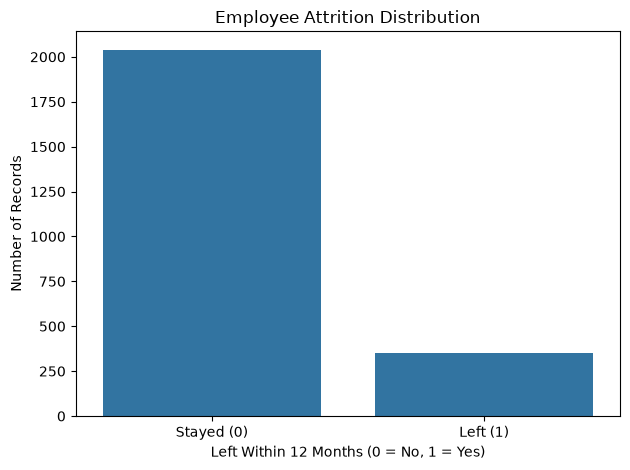

In [21]:
# Visualize the attrition label distribution
sns.countplot(data=df, x="left_within_12m")

plt.title("Employee Attrition Distribution")
plt.xlabel("Left Within 12 Months (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Stayed (0)", "Left (1)"])

plt.tight_layout()
plt.show()

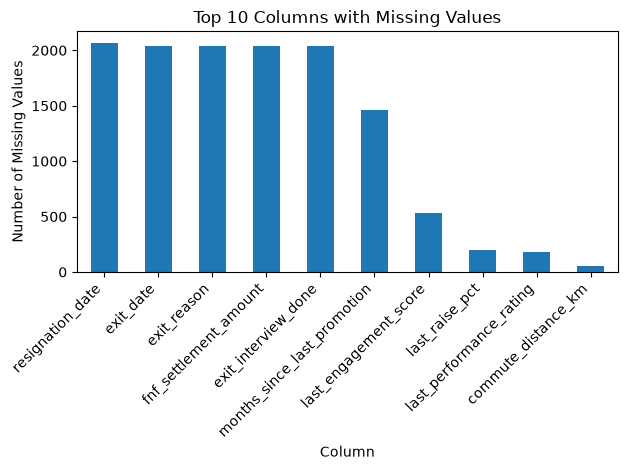

In [22]:
# Select columns that contain missing values
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

# Plot the 10 columns with the most missing values
if not missing_counts.empty:
    missing_counts.head(10).plot(kind="bar")

    plt.title("Top 10 Columns with Missing Values")
    plt.xlabel("Column")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.savefig(
    "/workspace/reports/missing_values_top10.png",
    dpi=150,
    bbox_inches="tight"
)
    plt.show()
else:
    print("No missing values found.")

## 10. Audit Findings and Data-Quality Decisions

This section summarizes the key findings from the dataset audit. The findings cover missing values, duplicate records, potential outliers, attrition class imbalance, and possible data leakage. These observations will guide preprocessing and feature selection in subsequent machine learning tasks.

In [23]:
# Summarize key dataset audit findings
audit_findings = pd.DataFrame({
    "Audit Check": [
        "Dataset Size",
        "Exact Duplicate Rows",
        "Repeated Employee IDs",
        "Attrition Label 0",
        "Attrition Label 1"
    ],
    "Finding": [
        f"{df.shape[0]} rows and {df.shape[1]} columns",
        str(df.duplicated().sum()),
        str(df["employee_id"].duplicated().sum()),
        str((df["left_within_12m"] == 0).sum()),
        str((df["left_within_12m"] == 1).sum())
    ]
})

display(audit_findings)

,Audit Check,Finding
0,Dataset Size,2389 rows and 42 columns
1,Exact Duplicate Rows,0
2,Repeated Employee IDs,6
3,Attrition Label 0,2040
4,Attrition Label 1,349


### 10.1 Data-Quality Decisions

The audit identified several areas that require attention before model development. Missing values will be handled according to the meaning of each feature. Repeated employee IDs will be investigated to distinguish legitimate historical records from data-quality issues. Potential outliers will be reviewed using the IQR and Z-score methods. The attrition target is imbalanced, with fewer employees leaving than staying. Target labels, identifiers, and information unavailable at the prediction date will be excluded from model inputs to prevent data leakage.

In [24]:
# Display the IQR and Z-score comparison
display(comparison_df)

,Feature,IQR Outliers,Z-score Outliers
0,annual_fixed_pay,94,26
1,avg_hours_worked_3m,48,15
2,tenure_months,74,42


In [25]:
%pip install tabulate
# Prepare the audit report
report = open("/workspace/reports/data-audit.md", "w")


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [34]:

# Generate the complete Task 1 audit report
from pathlib import Path

report_path = Path("/workspace/reports/data-audit.md")
report_path.parent.mkdir(parents=True, exist_ok=True)

# Missing-value summary
missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (df.isnull().mean().values * 100).round(2)
})
missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

# Check repeated employee IDs
duplicate_without_row_id = df.drop(columns=["row_id"]).duplicated().sum()

# Check category values for whitespace/capitalization differences.
# This identifies candidates for review; it does not automatically change data.
category_columns = df.select_dtypes(include=["object", "string"]).columns
category_issues = []

for column in category_columns:
    values = df[column].dropna().astype(str)
    normalized = values.str.strip().str.casefold()

    if values.nunique() > normalized.nunique():
        category_issues.append({
            "Column": column,
            "Raw unique values": values.nunique(),
            "Normalized unique values": normalized.nunique()
        })

category_report = pd.DataFrame(
    category_issues,
    columns=["Column", "Raw unique values", "Normalized unique values"]
)

# Check known bounded measurements and non-negative numeric fields.
invalid_checks = []

bounded_ranges = {
    "attendance_rate_3m": (0, 1),
    "wfh_share_3m": (0, 1),
    "last_performance_rating": (1, 5),
    "last_engagement_score": (1, 5)
}

for column, (lower, upper) in bounded_ranges.items():
    if column in df.columns:
        invalid = df[column].notna() & (
            (df[column] < lower) | (df[column] > upper)
        )
        invalid_checks.append({
            "Column": column,
            "Validation rule": f"{lower} to {upper}",
            "Invalid non-missing values": int(invalid.sum())
        })

for column in [
    "tenure_months",
    "total_experience_years",
    "previous_employers_count",
    "commute_distance_km",
    "annual_fixed_pay",
    "raises_received",
    "promotions_received",
    "late_arrivals_3m",
    "avg_overtime_hours_per_month_3m",
    "avg_hours_worked_3m",
    "unpaid_leave_days_6m",
    "paid_leave_days_6m"
]:
    if column in df.columns:
        invalid = df[column].notna() & (df[column] < 0)
        invalid_checks.append({
            "Column": column,
            "Validation rule": "Non-negative",
            "Invalid non-missing values": int(invalid.sum())
        })

invalid_report = pd.DataFrame(
    invalid_checks,
    columns=["Column", "Validation rule", "Invalid non-missing values"]
)

with report_path.open("w", encoding="utf-8") as report:
    report.write("# Task 1: Employee Attrition Data Audit\n\n")

    report.write("## 1. Objective\n\n")
    report.write(
        "Audit the employee attrition dataset before feature engineering "
        "and model development. The audit covers structure, missing values, "
        "duplicates, outliers, categories, invalid measurements, class "
        "imbalance and potential data leakage.\n\n"
    )

    report.write("## 2. Dataset Overview\n\n")
    report.write(f"- Rows: {df.shape[0]}\n")
    report.write(f"- Columns: {df.shape[1]}\n")
    report.write(f"- Numeric columns: {len(df.select_dtypes(include=np.number).columns)}\n")
    report.write(f"- Exact duplicate rows: {df.duplicated().sum()}\n\n")

    report.write("### Column data types\n\n")
    dtype_report = pd.DataFrame({
        "Column": df.columns,
        "Data type": df.dtypes.astype(str).values,
        "Missing count": df.isnull().sum().values
    })
    report.write(dtype_report.to_markdown(index=False))
    report.write("\n\n")

    report.write("## 3. Missing-Value Analysis\n\n")
    report.write(
        f"Columns containing missing values: {len(missing_report)} "
        f"out of {df.shape[1]}.\n\n"
    )
    if missing_report.empty:
        report.write("No missing values were found.\n\n")
    else:
        report.write(missing_report.to_markdown(index=False))
        report.write("\n\n")

    report.write("## 4. Duplicate Record Analysis\n\n")
    report.write(f"- Exact duplicate rows: {df.duplicated().sum()}\n")
    report.write(f"- Duplicate row IDs: {df['row_id'].duplicated().sum()}\n")
    report.write(
        f"- Repeated employee ID occurrences: "
        f"{df['employee_id'].duplicated().sum()}\n"
    )
    report.write(
        f"- Duplicate rows after excluding `row_id`: "
        f"{duplicate_without_row_id}\n\n"
    )
    report.write(
        "The six repeated employee records differ only by `row_id` in the "
        "notebook inspection. Investigate the source and intended meaning "
        "of these records before deciding whether to remove them.\n\n"
    )

    report.write("## 5. Attrition Distribution\n\n")
    attrition_report = pd.DataFrame({
        "Outcome": ["Stayed", "Left"],
        "Records": [
            int((df["left_within_12m"] == 0).sum()),
            int((df["left_within_12m"] == 1).sum())
        ],
        "Percentage": [
            round((df["left_within_12m"] == 0).mean() * 100, 2),
            round((df["left_within_12m"] == 1).mean() * 100, 2)
        ]
    })
    report.write(attrition_report.to_markdown(index=False))
    report.write(
        "\n\nThe target is imbalanced. Evaluate future models with "
        "precision, recall, F1-score and suitable threshold-independent "
        "metrics in addition to accuracy.\n\n"
    )

    report.write("## 6. Outlier Detection\n\n")
    report.write(comparison_df.to_markdown(index=False))
    report.write(
        "\n\nIQR and Z-score methods flag potential outliers using different "
        "criteria. A flagged observation is not automatically an error; "
        "investigate plausible extreme values before excluding them.\n\n"
    )

    report.write("## 7. Category Consistency Checks\n\n")
    if category_report.empty:
        report.write(
            "No differences in unique-category counts were detected by "
            "trimming whitespace and ignoring case. This check does not "
            "rule out every possible category inconsistency.\n\n"
        )
    else:
        report.write(
            "The following columns have category values that collapse "
            "to fewer unique values after trimming whitespace and ignoring "
            "case. Review them before normalizing categories.\n\n"
        )
        report.write(category_report.to_markdown(index=False))
        report.write("\n\n")

    report.write("## 8. Invalid Measurement Checks\n\n")
    report.write(
        "These checks flag values outside the stated bounds or negative "
        "values in fields expected to be non-negative. Confirm each rule "
        "against the data dictionary before correcting any record.\n\n"
    )
    report.write(invalid_report.to_markdown(index=False))
    report.write("\n\n")

    report.write("## 9. Data Leakage Review\n\n")
    leakage_table = pd.DataFrame({
        "Column": [
            "row_id", "employee_id", "observation_date",
            "left_within_12m", "voluntary_left_within_12m",
            "exit_date", "resignation_date", "exit_reason",
            "exit_interview_done", "fnf_settlement_amount"
        ],
        "Decision": [
            "Exclude from model inputs",
            "Exclude from model inputs",
            "Use to enforce the prediction-time boundary",
            "Target label; never use as an input feature",
            "Outcome-related label; never use as an input feature",
            "Exclude: exit outcome information",
            "Exclude: resignation outcome information",
            "Exclude: post-outcome information",
            "Exclude: post-outcome information",
            "Exclude: post-outcome information"
        ]
    })
    report.write(leakage_table.to_markdown(index=False))
    report.write(
        "\n\nMonthly attendance and payroll features must not use records "
        "after the relevant observation date. The target is "
        "`left_within_12m`.\n\n"
    )

    report.write("## 10. Data-Quality Decisions\n\n")
    decisions = pd.DataFrame([
        ["Missing numeric values", "Use training-fitted imputation where appropriate."],
        ["Missing categorical values", "Use training-fitted categorical imputation where appropriate."],
        ["Repeated employee IDs", "Investigate record meaning before removing records."],
        ["Potential outliers", "Investigate; do not automatically delete plausible extremes."],
        ["Category inconsistencies", "Review and normalize equivalent values consistently."],
        ["Invalid measurements", "Validate against the data dictionary and document any correction."],
        ["Target and post-outcome fields", "Exclude from predictive input features."],
        ["Employee identifiers", "Exclude from predictive input features."],
        ["Class imbalance", "Use appropriate classification metrics during model evaluation."]
    ], columns=["Issue", "Decision"])
    report.write(decisions.to_markdown(index=False))
    report.write("\n\n")

    report.write("## 11. Answer-Key Comparison\n\n")
    report.write(
        "Pending: compare these findings with the supplied answer-key notes "
        "and planted-issue material. Record which issues were initially "
        "missed and what decisions changed. This comparison has not been "
        "verified from the uploaded notebook alone.\n\n"
    )

    report.write("## 12. Conclusion\n\n")
    report.write(
        "The audit documents dataset structure, missingness, repeated "
        "records, class imbalance, outlier counts, category consistency "
        "checks, bounded/non-negative measurement checks and leakage "
        "decisions. These findings provide the basis for consistent "
        "preprocessing and feature engineering. The answer-key comparison "
        "must be completed before claiming the audit is fully reconciled.\n"
    )

print(f"Audit report saved successfully: {report_path}")


Audit report saved successfully: /workspace/reports/data-audit.md


In [27]:
repeated_employees = df[
    df["employee_id"].duplicated(keep=False)
].sort_values("employee_id")

display(
    repeated_employees[
        [
            "employee_id",
            "observation_date",
            "left_within_12m"
        ]
    ]
)

,employee_id,observation_date,left_within_12m
26,EMP-0060,2025-09-30,0
2386,EMP-0060,2025-09-30,0
100,EMP-0237,2025-09-30,0
2387,EMP-0237,2025-09-30,0
101,EMP-0238,2025-09-30,0
2384,EMP-0238,2025-09-30,0
150,EMP-0325,2025-09-30,0
2383,EMP-0325,2025-09-30,0
250,EMP-0483,2025-09-30,0
2385,EMP-0483,2025-09-30,0


In [28]:
# Check whether repeated employee records are identical

repeated_id_counts = df["employee_id"].value_counts()
repeated_id_counts = repeated_id_counts[
    repeated_id_counts > 1
]

for employee_id in repeated_id_counts.index:

    employee_records = df[
        df["employee_id"] == employee_id
    ]

    first_record = employee_records.iloc[0]
    second_record = employee_records.iloc[1]

    different_columns = []

    for column in df.columns:
        if not (
            pd.isna(first_record[column])
            and pd.isna(second_record[column])
        ) and first_record[column] != second_record[column]:

            different_columns.append(column)

    print("\nEmployee ID:", employee_id)
    print("Number of different columns:", len(different_columns))
    print("Different columns:", different_columns)


Employee ID: EMP-0060
Number of different columns: 1
Different columns: ['row_id']

Employee ID: EMP-0237
Number of different columns: 1
Different columns: ['row_id']

Employee ID: EMP-0238
Number of different columns: 1
Different columns: ['row_id']

Employee ID: EMP-0325
Number of different columns: 1
Different columns: ['row_id']

Employee ID: EMP-0483
Number of different columns: 1
Different columns: ['row_id']

Employee ID: EMP-0570
Number of different columns: 1
Different columns: ['row_id']


In [29]:
# Check duplicates while ignoring the row_id column
duplicate_without_row_id = df.drop(
    columns=["row_id"]
).duplicated().sum()

print(
    "Duplicate rows excluding row_id:",
    duplicate_without_row_id
)

Duplicate rows excluding row_id: 6


In [30]:
# Load the data dictionary
dictionary_df = pd.read_csv("/workspace/data/data_dictionary.csv")

# Display its column names
print("Data dictionary columns:")
print(dictionary_df.columns.tolist())

# Display the first five rows
display(dictionary_df.head())

Data dictionary columns:
['sheet', 'column', 'data_type', 'description', 'null_count', 'null_percent', 'distinct_values', 'example']


,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
0,attrition_dataset,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,attrition_dataset,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,attrition_dataset,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,attrition_dataset,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,attrition_dataset,role_id,text,Job role code from the roles table.,0,0.0,48,R047


In [31]:
# Select the data dictionary entries for our dataset
attrition_dictionary = dictionary_df[
    dictionary_df["sheet"] == "attrition_dataset"
]

# Display all column definitions
display(
    attrition_dictionary[
        [
            "column",
            "data_type",
            "description",
            "null_count",
            "null_percent"
        ]
    ]
)

,column,data_type,description,null_count,null_percent
0,row_id,integer,Row number in the sheet.,0,0.0
1,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0
2,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0
3,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0
4,role_id,text,Job role code from the roles table.,0,0.0
5,job_level,integer,"Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).",0,0.0
6,work_location,text,City of the office the employee is attached to.,0,0.0
7,work_mode,text,"Onsite, Hybrid or Remote.",0,0.0
8,employment_type,text,Permanent or Fixed-Term Contract. Contract sta...,0,0.0
9,highest_education,text,Highest qualification (may be blank).,15,0.6


In [32]:
# Find dataset columns missing from the dictionary
dataset_columns = set(df.columns)
dictionary_columns = set(attrition_dictionary["column"])

missing_from_dictionary = dataset_columns - dictionary_columns

print("Dataset columns:", len(dataset_columns))
print("Dictionary entries:", len(dictionary_columns))
print("Columns missing from dictionary:", missing_from_dictionary)

Dataset columns: 42
Dictionary entries: 42
Columns missing from dictionary: set()


In [33]:
# Columns that may cause data leakage
leakage_columns = [
    "observation_date",
    "left_within_12m",
    "voluntary_left_within_12m",
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount"
]

# Display their definitions from the data dictionary
display(
    attrition_dictionary[
        attrition_dictionary["column"].isin(leakage_columns)
    ][["column", "data_type", "description", "null_percent"]]
)

,column,data_type,description,null_percent
2,observation_date,date,Date the features were measured (30 Sep 2025 f...,0.0
34,left_within_12m,integer,LABEL: 1 if the employee left within 12 months...,0.0
35,voluntary_left_within_12m,integer,1 if the exit was a resignation.,0.0
37,exit_date,date,Last working day; blank for active employees.,85.4
38,resignation_date,date,Date resignation was submitted (voluntary leav...,86.6
39,exit_reason,text,Reason recorded at exit. POST-OUTCOME informat...,85.4
40,exit_interview_done,text,Y if an exit interview was held. POST-OUTCOME:...,85.4
41,fnf_settlement_amount,decimal,Full and final settlement paid at exit. POST-O...,85.4
